In [5]:
!pip install --upgrade pip


In [6]:
!pip install arabic-reshaper==2.1.4


  Using cached arabic_reshaper-2.1.4-py3-none-any.whl.metadata (12 kB)
  Using cached future-1.0.0-py3-none-any.whl.metadata (4.0 kB)
Using cached arabic_reshaper-2.1.4-py3-none-any.whl (20 kB)
Using cached future-1.0.0-py3-none-any.whl (491 kB)


In [7]:
!pip install opencv-python-headless 

  Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (49.9 MB)


In [8]:
!pip install git+https://github.com/Belval/TextRecognitionDataGenerator.git --no-deps


  Cloning https://github.com/Belval/TextRecognitionDataGenerator.git to /tmp/pip-req-build-ywjmxa74
  Running command git clone --filter=blob:none --quiet https://github.com/Belval/TextRecognitionDataGenerator.git /tmp/pip-req-build-ywjmxa74
  Resolved https://github.com/Belval/TextRecognitionDataGenerator.git to commit dd9d7d3886fc2cf5a1e3228445c6651e3f53654c
  Preparing metadata (setup.py) ... done
  Created wheel for trdg: filename=trdg-1.8.0-py3-none-any.whl size=98624347 sha256=de66360e72718c782d2cef33e1d58119121cf89386a50385e24a5a53b7a9d1a9
  Stored in directory: /tmp/pip-ephem-wheel-cache-wef7jmvi/wheels/37/0d/6b/853a749bc3ab2ed3d9e5801efd688ff91278b8d8c4d967ade4
Successfully built trdg


In [9]:
!pip install python-bidi

  Using cached python_bidi-0.6.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.9 kB)
Using cached python_bidi-0.6.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (286 kB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
trdg 1.8.0 requires diffimg==0.2.3, which is not installed.
trdg 1.8.0 requires opencv-python>=4.2.0.32, which is not installed.
trdg 1.8.0 requires wikipedia>=1.4.0, which is not installed.
trdg 1.8.0 requires arabic-reshaper==2.1.3, but you have arabic-reshaper 2.1.4 which is incompatible.
trdg 1.8.0 requires python-bidi==0.4.2, but you have python-bidi 0.6.3 which is incompatible.


In [10]:
!pip install wikipedia

  Using cached wikipedia-1.4.0-py3-none-any.whl
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
trdg 1.8.0 requires diffimg==0.2.3, which is not installed.
trdg 1.8.0 requires opencv-python>=4.2.0.32, which is not installed.
trdg 1.8.0 requires arabic-reshaper==2.1.3, but you have arabic-reshaper 2.1.4 which is incompatible.
trdg 1.8.0 requires python-bidi==0.4.2, but you have python-bidi 0.6.3 which is incompatible.


In [11]:
from trdg.generators import GeneratorFromDict
from collections import Counter
from tqdm.auto import tqdm
import os

Missing modules for handwritten text generation.


In [9]:
!unzip fonts.zip

Archive:  fonts.zip
   creating: fonts/
   creating: fonts/ankh-sanctuary-font/
  inflating: fonts/ankh-sanctuary-font/AnkhSanctuary-PVK0B.ttf  
  inflating: fonts/ankh-sanctuary-font/info.txt  
   creating: fonts/ankh-sanctuary-font/misc/
  inflating: fonts/ankh-sanctuary-font/misc/FSLA_NonCommercial_License-d5e8.html  
  inflating: fonts/ankh-sanctuary-font/misc/Get Commercial License-cca5.url  
   creating: fonts/autumn-flowers-font/
  inflating: fonts/autumn-flowers-font/AutumnFlowers-9YVZK.otf  
  inflating: fonts/autumn-flowers-font/info.txt  
   creating: fonts/autumn-flowers-font/misc/
  inflating: fonts/autumn-flowers-font/misc/Read Me!!.txt  
   creating: fonts/black-north-font/
  inflating: fonts/black-north-font/Blacknorthdemo-mLE25.otf  
  inflating: fonts/black-north-font/info.txt  
   creating: fonts/black-north-font/misc/
  inflating: fonts/black-north-font/misc/READ FIRST.pdf  
   creating: fonts/coffee-healing-font/
  inflating: fonts/coffee-healing-font/CoffeeHealing

In [2]:
!unzip fonts2.zip

Archive:  fonts2.zip
   creating: fonts2/
   creating: fonts2/70s-disco-font/
  inflating: fonts2/70s-disco-font/70SdiscopersonaluseBold-w14z2.otf  
  inflating: fonts2/70s-disco-font/info.txt  
   creating: fonts2/70s-disco-font/misc/
  inflating: fonts2/70s-disco-font/misc/! ! ! TERMS OF USE.txt  
   creating: fonts2/air-travelers-font/
  inflating: fonts2/air-travelers-font/AirtravelerspersonaluseBdit-gxgyE.otf  
  inflating: fonts2/air-travelers-font/AirtravelerspersonaluseBdit-ow59x.otf  
  inflating: fonts2/air-travelers-font/info.txt  
   creating: fonts2/air-travelers-font/misc/
  inflating: fonts2/air-travelers-font/misc/! ! ! TERMS OF USE.txt  
   creating: fonts2/ananda-black-font/
  inflating: fonts2/ananda-black-font/AnandaBlackPersonalUseRegular-rg9Rx.ttf  
  inflating: fonts2/ananda-black-font/info.txt  
   creating: fonts2/ananda-black-font/misc/
  inflating: fonts2/ananda-black-font/misc/! ! ! TERMS OF USE.txt  
   creating: fonts2/atop-font/
  inflating: fonts2/atop-f

In [29]:
import os
import random
from trdg.generators import GeneratorFromDict
from tqdm import tqdm


if not os.path.exists("synthdata"):
    os.mkdir("synthdata")

images = []
labels = []

fonts = [
    "fonts/ankh-sanctuary-font/AnkhSanctuary-PVK0B.ttf",
    "fonts/autumn-flowers-font/AutumnFlowers-9YVZK.otf",
    "fonts/black-north-font/Blacknorthdemo-mLE25.otf",
    "fonts/coffee-healing-font/CoffeeHealing-1GrKe.ttf",
    "fonts/creamy-sugar-font/CreamySugar-gxnGR.ttf",
    "fonts/crotah-font/CrotahFreeVersionItalic-z8Ev3.ttf",
    "fonts/drip-october-font/DripOctober-vm0JA.ttf",
    "fonts/florisa-font/FlorisaPersonalUse-nRm84.otf",
    "fonts/matcha-font/Matcha-EaLge.ttf",
    "fonts/nesto-copper-42-font/Nestocopper42-1GVw2.ttf",
    "fonts/pumpkin-type-halloween-font/PumpkinTypeHalloween-8MVEg.ttf"
]


for i in range(1000):
    selected_font = random.choice(fonts)
    generator = GeneratorFromDict(
        count=100, 
        stroke_width=2,  
        stroke_fill="#000000",  
        word_split=False,  
        output_mask=False,  
        character_spacing=2, 
        fit=True,  
        margins=(5, 5, 5, 5),  
        text_color="#000000,#FFFFFF", 
        language="en",  #
        fonts=[selected_font],  
    )

    for img, lbl in tqdm(generator):
        path = f'synthdata/{lbl}.png'
        img.save(path)
        images.append(path)
        labels.append(lbl)


100it [00:02, 46.33it/s]
100it [00:02, 38.21it/s]
100it [00:00, 120.92it/s]
100it [00:01, 93.11it/s]
100it [00:01, 85.25it/s]
100it [00:02, 39.97it/s]
100it [00:03, 26.87it/s]
100it [00:02, 45.67it/s]
100it [00:02, 38.64it/s]
100it [00:00, 121.88it/s]
100it [00:01, 94.74it/s]
100it [00:02, 37.47it/s]
100it [00:01, 87.83it/s]
100it [00:02, 45.40it/s]
100it [00:02, 33.34it/s]
100it [00:02, 44.18it/s]
100it [00:02, 37.31it/s]
100it [00:02, 33.68it/s]
100it [00:01, 87.89it/s]
100it [00:01, 88.06it/s]
100it [00:01, 60.06it/s]
100it [00:02, 47.99it/s]
100it [00:02, 38.02it/s]
100it [00:02, 40.20it/s]
100it [00:03, 25.74it/s]
100it [00:01, 54.98it/s]
100it [00:00, 114.84it/s]
100it [00:03, 26.19it/s]
100it [00:03, 25.82it/s]
100it [00:02, 37.07it/s]
100it [00:02, 36.88it/s]
100it [00:01, 58.29it/s]
100it [00:01, 83.65it/s]
100it [00:03, 27.02it/s]
100it [00:01, 84.77it/s]
100it [00:03, 25.93it/s]
100it [00:00, 122.72it/s]
100it [00:02, 40.47it/s]
100it [00:01, 56.66it/s]
100it [00:01, 58.35it

In [30]:
file_path = 'synthdata' 
file_size = os.path.getsize(file_path)
print(f"File size: {file_size / (1024 * 1024):.2f} MB")  

File size: 2.87 MB


In [31]:
count = 0
for path in os.listdir(file_path):
    if os.path.isfile(os.path.join(file_path, path)):
        count += 1
print('File count:', count)

File count: 90031


In [20]:
!unzip fontt.zip

Archive:  fontt.zip
   creating: fontt/
   creating: fontt/dk_longreach/
  inflating: fontt/dk_longreach/DK Longreach.otf  
  inflating: fontt/dk_longreach/Hanoded Fonts License & FAQ - DO READ THIS!.pdf  
  inflating: fontt/dk_longreach/Longreach Poster 1.png  
   creating: fontt/hello_baby_karl_sans/
  inflating: fontt/hello_baby_karl_sans/Hello Baby Karl Sans.ttf  
  inflating: fontt/hello_baby_karl_sans/Hello Baby Karl Script.ttf  
   creating: fontt/lobster/
   creating: fontt/lobster/Font Lab Source/
  inflating: fontt/lobster/Font Lab Source/Lobster 1.4 merged and optimized.vfb  
  inflating: fontt/lobster/Font Lab Source/LobsterSource.vfb  
  inflating: fontt/lobster/License.txt  
  inflating: fontt/lobster/Lobster 1.4.otf  
  inflating: fontt/lobster/Readme.txt  
   creating: fontt/loki_cola/
  inflating: fontt/loki_cola/cocacola.ttf  
  inflating: fontt/loki_cola/LOKICOLA.TTF  
  inflating: fontt/loki_cola/readme.txt  
   creating: fontt/philosopher/
  inflating: fontt/philos

In [12]:
import random
from typing import List, Tuple
from trdg.generators import (
    GeneratorFromDict,
    GeneratorFromRandom,
    GeneratorFromStrings,
    GeneratorFromWikipedia,
)
from trdg.generators.from_strings import GeneratorFromStrings
from trdg.data_generator import FakeTextDataGenerator
from trdg.string_generator import create_strings_from_wikipedia
from trdg.utils import load_dict, load_fonts

if not os.path.exists("synthdata2"):
    os.mkdir("synthdata2")
    
fonts2=['fonts2/70s-disco-font/70SdiscopersonaluseBold-w14z2.otf',
       'fonts2/air-travelers-font/AirtravelerspersonaluseBdit-gxgyE.otf',
       'fonts2/ananda-black-font/AnandaBlackPersonalUseRegular-rg9Rx.ttf',
       'fonts2/atop-font/Atop-R99O3.ttf',
       'fonts2/goldensun-font/GoldensunpersonaluseBold-z8WBl.otf',
       'fonts2/goldrops-font/GoldropspersonaluseRegular-9Ynn5.otf',
       'fonts2/moonkids-ext-bd-font/MoonkidsPersonalUseExtbd-gxPZ3.ttf',
       'fonts2/nature-beauty-font/NatureBeautyPersonalUse-9Y2DK.ttf',
       'fonts2/queensides-font/QueensidesMedium-x30zV.ttf',
       'fonts2/sporting-outline-font/SportingOutline-x3e85.ttf',
       'fonts2/super-woobly-font/SuperWoobly-8MJlz.ttf']
fonts = [
    "fonts/ankh-sanctuary-font/AnkhSanctuary-PVK0B.ttf",
    "fonts/autumn-flowers-font/AutumnFlowers-9YVZK.otf",
    "fonts/black-north-font/Blacknorthdemo-mLE25.otf",
    "fonts/coffee-healing-font/CoffeeHealing-1GrKe.ttf",
    "fonts/creamy-sugar-font/CreamySugar-gxnGR.ttf",
    "fonts/crotah-font/CrotahFreeVersionItalic-z8Ev3.ttf",
    "fonts/drip-october-font/DripOctober-vm0JA.ttf",
    "fonts/florisa-font/FlorisaPersonalUse-nRm84.otf",
    "fonts/matcha-font/Matcha-EaLge.ttf",
    "fonts/nesto-copper-42-font/Nestocopper42-1GVw2.ttf",
    "fonts/pumpkin-type-halloween-font/PumpkinTypeHalloween-8MVEg.ttf"
]
fonts+=fonts2

images = []
labels = []




for i in range(1):
    selected_font = random.choice(fonts)
    generator = GeneratorFromDict(
        count=50, 
        stroke_width=2,  
        stroke_fill="#000000",  
        word_split=False,  
        output_mask=False,  
        character_spacing=2, 
        fit=True,
        random_skew=True,
        random_blur=True,
        margins=(5, 5, 5, 5), 
        text_color="#000000,#FFFFFF", 
        language="en",  
        background_type=2,
        fonts=[selected_font],  
    )

    for img, lbl in tqdm(generator):
        path = f'synthdata2/{lbl}.png'
        img.save(path)
        images.append(path)
        labels.append(lbl)

       

0it [00:00, ?it/s]

In [20]:
from tqdm import tqdm
import random
import os
from trdg.generators import GeneratorFromDict

# Create the output directory if it doesn't exist
if not os.path.exists("synthdata"):
    os.mkdir("synthdata")

fonts2 = [
    'fonts2/70s-disco-font/70SdiscopersonaluseBold-w14z2.otf',
    'fonts2/air-travelers-font/AirtravelerspersonaluseBdit-gxgyE.otf',
    'fonts2/ananda-black-font/AnandaBlackPersonalUseRegular-rg9Rx.ttf',
    'fonts2/atop-font/Atop-R99O3.ttf',
    'fonts2/goldensun-font/GoldensunpersonaluseBold-z8WBl.otf',
    'fonts2/goldrops-font/GoldropspersonaluseRegular-9Ynn5.otf',
    'fonts2/moonkids-ext-bd-font/MoonkidsPersonalUseExtbd-gxPZ3.ttf',
    'fonts2/nature-beauty-font/NatureBeautyPersonalUse-9Y2DK.ttf',
    'fonts2/queensides-font/QueensidesMedium-x30zV.ttf',
    'fonts2/sporting-outline-font/SportingOutline-x3e85.ttf',
    'fonts2/super-woobly-font/SuperWoobly-8MJlz.ttf'
]

fonts = [
    "fonts/ankh-sanctuary-font/AnkhSanctuary-PVK0B.ttf",
    "fonts/autumn-flowers-font/AutumnFlowers-9YVZK.otf",
    "fonts/black-north-font/Blacknorthdemo-mLE25.otf",
    "fonts/coffee-healing-font/CoffeeHealing-1GrKe.ttf",
    "fonts/creamy-sugar-font/CreamySugar-gxnGR.ttf",
    "fonts/crotah-font/CrotahFreeVersionItalic-z8Ev3.ttf",
    "fonts/drip-october-font/DripOctober-vm0JA.ttf",
    "fonts/florisa-font/FlorisaPersonalUse-nRm84.otf",
    "fonts/matcha-font/Matcha-EaLge.ttf",
    "fonts/nesto-copper-42-font/Nestocopper42-1GVw2.ttf",
    "fonts/pumpkin-type-halloween-font/PumpkinTypeHalloween-8MVEg.ttf"
]
fonts += fonts2

images = []
labels = []

for i in range(1200):
    selected_font = random.choice(fonts)
    generator = GeneratorFromDict(
        count=100,
        stroke_width=3,  # Increase stroke for added noise
        stroke_fill="#222222",  # Dark gray strokes
        word_split=False,
        output_mask=False,
        character_spacing=4,  # Increase spacing for visual noise
        fit=False,  # Allow text to overflow boundaries
        random_skew=True,
        random_blur=True,  # Enable random blur
        margins=(10, 10, 10, 10),  # Increase margins
        text_color="#000000,#FFFFFF,#FF0000,#00FF00",  # Mixed colors for added visual noise
        language="en",
        background_type=2,  # Use natural image backgrounds
        orientation=0,  # Horizontal text
        distorsion_type=2,  # Sine wave distortion
        distorsion_orientation=2,  # Both horizontal and vertical distortions
        fonts=[selected_font],
    )

    for img, lbl in tqdm(generator):
        path = f'synthdata/{lbl}.png'
        img.save(path)
        images.append(path)
        labels.append(lbl)


100it [00:07, 12.51it/s]
100it [00:09, 10.57it/s]
100it [00:09, 10.56it/s]
100it [00:11,  9.02it/s]
100it [00:06, 14.87it/s]
100it [00:07, 13.37it/s]
100it [00:09, 10.04it/s]
100it [00:06, 14.94it/s]
100it [00:10,  9.96it/s]
100it [00:06, 16.04it/s]
100it [00:05, 17.98it/s]
100it [00:09, 10.86it/s]
100it [00:06, 15.66it/s]
100it [00:07, 13.77it/s]
100it [00:08, 11.84it/s]
100it [00:10,  9.43it/s]
100it [00:06, 15.71it/s]
100it [00:07, 14.12it/s]
100it [00:14,  6.75it/s]
100it [00:09, 10.02it/s]
100it [00:08, 11.16it/s]
100it [00:06, 15.02it/s]
100it [00:08, 12.40it/s]
100it [00:07, 12.53it/s]
100it [00:09, 11.07it/s]
100it [00:08, 11.23it/s]
100it [00:06, 15.61it/s]
100it [00:06, 15.78it/s]
100it [00:17,  5.62it/s]
100it [00:09, 10.55it/s]
100it [00:08, 12.04it/s]
100it [00:07, 14.08it/s]
100it [00:08, 12.31it/s]
100it [00:06, 15.78it/s]
100it [00:06, 14.86it/s]
100it [00:09, 10.15it/s]
100it [00:11,  8.83it/s]
100it [00:06, 15.00it/s]
100it [00:17,  5.65it/s]
100it [00:17,  5.61it/s]


In [23]:
file_path='synthdata'
count = 0
for path in os.listdir(file_path):
    if os.path.isfile(os.path.join(file_path, path)):
        count += 1
print('File count:', count)

File count: 105856


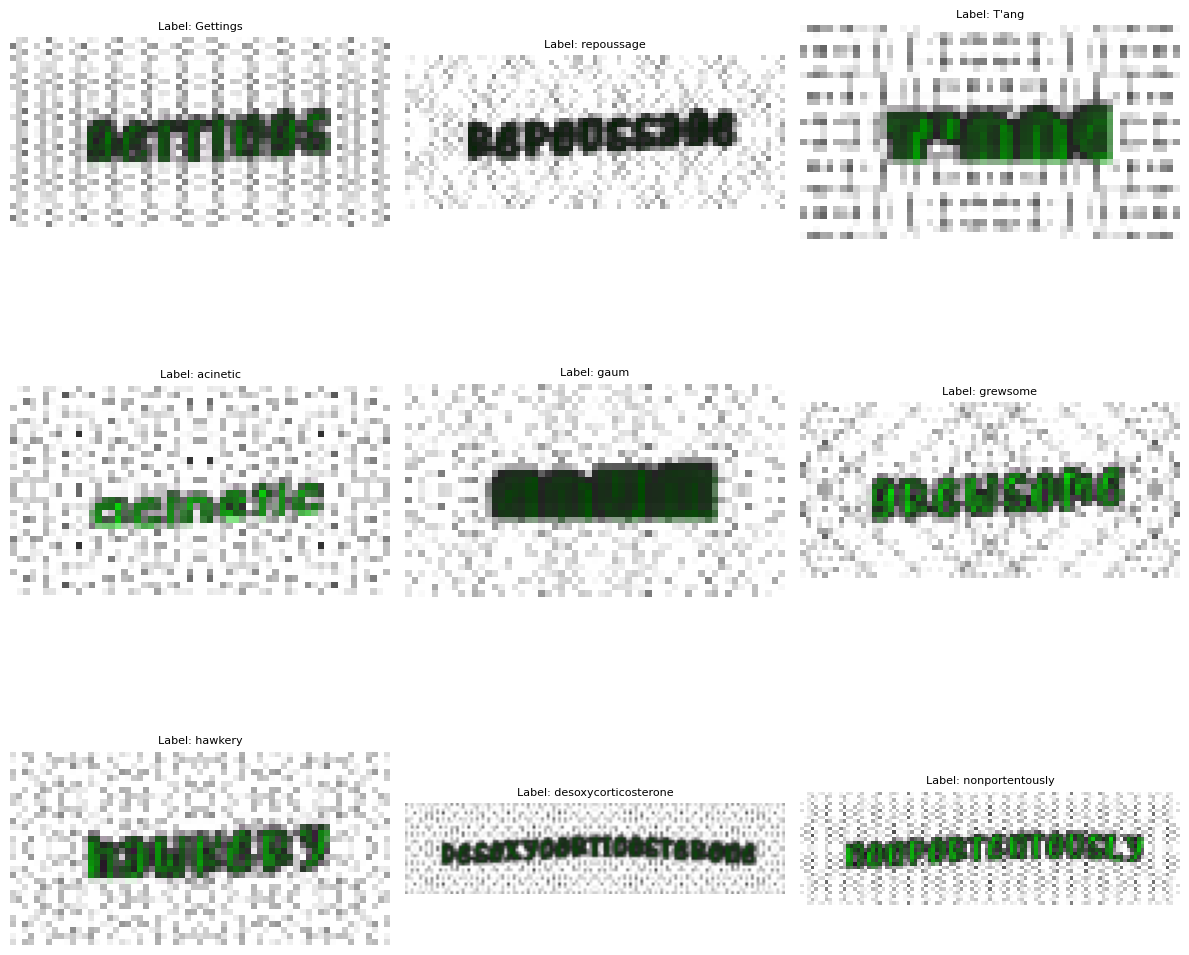

In [24]:
import matplotlib.pyplot as plt
from PIL import Image

def visualize_images(image_paths, rows=3, cols=3):
    fig, axes = plt.subplots(rows, cols, figsize=(12, 12))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        if i < len(image_paths):
            img = Image.open(image_paths[i])
            ax.imshow(img)
            ax.set_title(f"Label: {labels[i]}", fontsize=8)  # Display corresponding label
            ax.axis("off")
        else:
            ax.axis("off")  # Turn off extra axes if not enough images

    plt.tight_layout()
    plt.show()

# Visualize a subset of images (e.g., first 9 images)
visualize_images(images[:9], rows=3, cols=3)
